# Numpyro

In [23]:
import os
#os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=4"

import numpyro
numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import jax.scipy as jscipy
import jax.random as jrand 

import numpyro.distributions as dist
from jax import vmap
from jax import jit
from jax import lax

import h5py
import json

from numpyro.infer import MCMC, NUTS

import arviz as az

import matplotlib.pyplot as plt

In [2]:
#constants
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

In [3]:
def find_indices(array_1d, min_val, max_val):
    '''
       Method for finding the indices to maintain order when placing min_val and max_val into a 1d array.
       This method is used to find bounds for a mask to be applied as a slice when computing the model function,
       the slicing will help to minimize function calls in the model.
    '''
    start = jnp.searchsorted(array_1d, min_val, side='left')
    end   = jnp.searchsorted(array_1d, max_val, side='right')
    return start, end

In [4]:
# def gaussian_pulse_row(applyto_array_1d, argument_array_1d, start, end, sigma):
#     '''
#         Method for slicing an array to only apply the gaussian pulse model to a subset of points, for one row.
#         applyto_array_1d: array to slice in order to only change a subset of its values
#         argument_array_1d: the arguments which are passed to exp, also sliced
#         start: first index for slicing
#         end: last index for slicing
#         sigma: std of gaussian
        
#     '''
#     #pick out the slice of arguments to pass to the gaussian function
#     length = end-start
#     args_slice = lax.dynamic_slice(argument_array_1d, (start,), (length,))
#     gaussian_pulse = jnp.exp(-0.5 * (args_slice / sigma) ** 2)
    
#     # gaussian_pulse = jnp.exp(-0.5 * (argument_array_1d[start:end] / sigma) ** 2)
    
#     # dynamically update slice
#     return lax.dynamic_update_slice(applyto_array_1d, gaussian_pulse, start)
    
# def gaussian_pulse_row_slice(applyto_array_1d, argument_array_1d, start, end, sigma):
#     gaussian_pulse = jnp.exp(-0.5 * (argument_array_1d[start:end] / sigma) ** 2) #static slice
#     return applyto_array_1d.at[start:end].set(gaussian_pulse)





# def gaussian_pulse_row_slice(argument_array_1d, applyto_array_2d, row, start, end, sigma):
#     '''
#         Method for slicing an array to only apply the gaussian pulse model to a subset of data points, for one row.
#         applyto_array_2d: 2d array to slice in order to only change a subset of its values in one row
#         argument_array_1d: the arguments which are passed to exp, also sliced
#         row: row of applyto_array_2d to slice
#         start: array of first indices for slicing, one index per row
#         end: array of last indices for slicing, one index per row
#         sigma: std of gaussian
        
#     '''    
#     gaussian_pulse = jnp.exp(-0.5 * (argument_array_1d[start[row]:end[row]] / sigma) ** 2)
#     gaussian_pulse = gaussian_pulse[None, :]
#     return lax.dynamic_update_slice(applyto_array_2d, gaussian_pulse, (row, start[row]))#inserts the pulse at the ith row, start[i]th column of the 2d array

# def apply_gaussian_per_row(argument_array_2d, applyto_array_2d, start, end, sigma):
#     '''
#         Method to insert sliced gaussian pulse into all rows of a 2d array, using arguments from another 2d array.
#     '''
#     n_rows = applyto_array_2d.shape[0]

#     def body_fun(i, mat):
#         mat = mat.at[i].set(
#             gaussian_pulse_row(argument_array_2d[i], applyto_array_2d, i, start[i], end[i], sigma)
#         )
#         return mat

#     return lax.fori_loop(0, n_rows, body_fun, applyto_array_2d)


def apply_gaussian_per_row(argument_array_2d, applyto_array_2d, startindex_array, endindex_array, sigma):

    n_rows = applyto_array_2d.shape[0]

    def body_fun(i, mat):

        length = endindex_array[i] - startindex_array[i] #length of slice

        args_slice = lax.dynamic_slice(
            argument_array_2d[i],
            (startindex_array[i],),
            (length,)
        )

        pulse = jnp.exp(-0.5 * (args_slice / sigma) ** 2)

        pulse = pulse[None, :]  # broadcast to correct shape for inserting into larger array

        return lax.dynamic_update_slice(mat, pulse, (i, startindex_array[i]))

    return lax.fori_loop(0, n_rows, body_fun, applyto_array_2d)

In [5]:
def single_pulse_model(params_dict,freqs,times, model_template=None):
    """
        Model of a single pulse, which will be summed in the forward model for multi-pulse signals.
        
        params_dict: dict of each parameter of the pulse
        freqs: array of frequency bins in the data
        times: array of time bins in the data
        model_template: an empty array of dimensions (nfreq, ntime) that will be a fixed data structure for model values to be put into, saves us from having to generate this for every call of this function and also allows us to slice out trivial model elements which equate to zero
    """

    # frequency array nu_k
    # shape of (nfreq,1), units of MHz, these are the rows of the model matrix
    # freqs = jnp.asarray(freq_array, dtype=jnp.float32)[:, None]
    
    # time array t_n
    # shape of (1,ntime), units of seconds, these are the columns of the model matrix
    # times = jnp.asarray(time_array, dtype=jnp.float32)[None, :]

    #params

    det_response = jnp.float32(1) # TO-DO: WILL BE FUNCTION LATER !!!! Maybe also convolution is involved if frequencies are not independent between channels
    
    freq_ref = jnp.float32(params_dict["freq_ref"]) # fixed reference / pivot EM frequency nu_r, set approximately equal to frequency of peak emission for a pulse with Gaussian-like SED in the dynamic spectrum element D_kn
    tau_ref = jnp.float32(params_dict["tau_ref"]) # fixed scatter broadening timescale at freq_ref; if 0, no scatter is put in the model
    
    alpha = jnp.float32(params_dict["alpha"]) # Base-10 exponent of amplitude for burst componnent
    gamma = jnp.float32(params_dict["gamma"]) # Spectral index for burst component
    beta = jnp.float32(params_dict["beta"]) # Spectral running for burst component

    delta = jnp.float32(params_dict["delta"]) # Exponent of frequency dependence for scatter-broadening
    epsilon = jnp.float32(params_dict["epsilon"]) # Exponent of frequency dependence for pulse dispersion
    mean_arrival_time = jnp.float32(params_dict["mean_arrival_time"]) # defined so that the pulse peaks at freq_ref at this time (before scatter or dispersion shifts at other frequencies)
    sigma = jnp.float32(params_dict["sigma"])
    
    DM = jnp.float32(params_dict["DM"]) # dispersion measure, pc/cm^3
    #k_DM = jnp.float32(params_dict.get("k_DM",(2.41*1e-4)**(-1)))# dispersion constant, (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    k_DM = jnp.float32(params_dict["k_DM"])# dispersion constant, (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
    normalized_freqs = freqs/freq_ref # nu_k / nu_r
    
    # model M_{kn}= ( A * F_k * T_kn)
    # A : global amplitude
    # F : frequency-dependent spectral energy distribution (SED)
    # T : dispersed temporal shape of pulse

    A = jnp.power(10, alpha)
    #print(A)

    kappa = gamma + ( beta*jnp.log(normalized_freqs) )#Running power law of SED
    F = normalized_freqs**kappa * det_response
    #print(F)

    mean_time_gaussian = mean_arrival_time + ( k_DM * DM * ( (freqs**epsilon) - (freq_ref**epsilon) ) ) #mean time in the gaussian model with no scatter broadening
    # return mean_time_gaussian
    
    taus = tau_ref * (normalized_freqs**delta) # Timescale of scattering-broadening at nu_k
    dispersed_times = (times - mean_time_gaussian) #dispersed timeseries wrt first time stamp
    #print(mean_time_gaussian-5*sigma)

    #TO-DO: rewrite as jnp.select instead of if else
    
    # if tau_ref !=0: #scatter broadening
    #     T = ((1/taus) * 0.5) * jnp.exp( (sigma**2) / (2 * taus**2) - (dispersed_times/taus) ) * (1 + jscipy.special.erf((dispersed_times - sigma*sigma/taus)/(jnp.sqrt(2) * sigma)))
    # else: #no scatter broadening
        # cutoff_array = jnp.ones(freqs.shape[0], dtype=jnp.float32)*(5*sigma)# we'll set a cutoff beyond which no function calls are actually made because the model is sufficiently close to zero
        # print(cutoff_array.shape)
        # start_index, end_index = vmap(find_indices)(dispersed_times,-cutoff_array,cutoff_array)# find times that will give function values within our cutoff, and get indices for slicing
        # print(start_index.shape,end_index.shape)
        
        # T = jnp.ones_like(dispersed_times) #by default, takes dtype of array in argument
        # print(T.shape)

        # T = apply_gaussian_per_row(dispersed_times, T, start_index, end_index, sigma)
        

    T = jnp.exp( - ((dispersed_times/sigma)**2) / 2 ) #note minus sign, corrects typo of fitburst paper
        #print(T)

    M = A * F *T

    return M

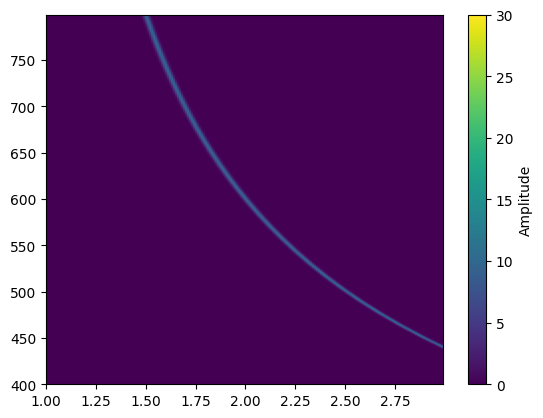

In [6]:
params_dict = {
    # Pulse and dispersion
    "DM": 100.0,           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": 0 ,#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 2.0,
    "k_DM": (2.41*1e-4)**(-1)

    
}

freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
#single_pulse_model(params_dict, freq_array, time_array)

M = (single_pulse_model(params_dict, freq_array, time_array))

plt.imshow(
    M,
    aspect='auto',
    origin='lower',
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30
)
plt.colorbar(label="Amplitude")


## Old model no slice

In [164]:
def frb_forward_model(params_list, freq_array, time_array):
    """
    Forward model for multi-pulse FRB as sum of single pulses.

    Parameters
    ----------
    params_list : list of dict
        Each dict contains parameters for a single pulse (as in single_pulse_model).
    freq_array : array (nfreq,)
        Frequency bins in MHz
    time_array : array (ntime,)
        Time bins in seconds

    Returns
    -------
    M : array (nfreq, ntime)
        Dynamic spectrum of the summed pulses
    """
    # Initialize model to zero
    M_total = jnp.zeros((len(freq_array), len(time_array)))

    # Sum over pulses
    for params_dict in params_list:
        M_total += single_pulse_model(params_dict, freq_array, time_array)

    return M_total

def numpyro_model(data, freq_array, time_array, n_pulses=1, sigma_noise=1):
    """
    Numpyro model for multi-pulse FRB.
    """

    params_list = []

    for i in range(n_pulses):
        # Priors for pulse i
        #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        DM = numpyro.sample(f"DM_{i}", dist.Uniform(-100, 100))
        #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(-0.1, 0.1))
        sigma = numpyro.sample(f"sigma_{i}", dist.Uniform(0.005, 0.1))
        alpha = numpyro.sample(f"alpha_{i}", dist.Uniform(0, 2.0))
        tau_ref = 0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        gamma = numpyro.sample(f"gamma_{i}", dist.Uniform(-10, 10))
        beta = numpyro.sample(f"beta_{i}", dist.Uniform(-1, 1))
        delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        
        # fixed / typical values
        freq_ref = 600.0
        # gamma = 0.0
        # beta = 0.0
        # delta = -4.0
        # epsilon = -2.0
        k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

        params_dict = {
            "DM": DM,
            "mean_arrival_time": mean_arrival_time,
            "sigma": sigma,
            "alpha": alpha,
            "tau_ref": tau_ref,
            "freq_ref": freq_ref,
            "gamma": gamma,
            "beta": beta,
            "delta": delta,
            "epsilon": epsilon,
            "k_DM": k_DM
        }

        params_list.append(params_dict)

    # Forward model: sum of pulses
    pred = frb_forward_model(params_list, freq_array, time_array)    
    
    # Sample from likelihood (Gaussian noise)
    numpyro.sample("obs", dist.Normal(pred, sigma_noise), obs=data)


## Run old model

### Fake data

In [221]:
params_dict = {
    # Pulse and dispersion
    "DM": 0.0,           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": 0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 0.0,
    "k_DM" : (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
}

# params_list = [params_dict]

# params_dict_2 = {
#     # Pulse and dispersion
#     "DM": 90.0,           # pc/cm^3
#     "freq_ref": 600.0,     # MHz, reference frequency near middle of band
#     "tau_ref": 0.000, # 0.015,      # s, scatter broadening at freq_ref
#     "epsilon": -2.0,        # dispersion exponent
    
#     # Temporal shape
#     "sigma": 0.01,        # s, intrinsic width of pulse
    
#     # Amplitude / spectrum
#     "alpha": 1.0,          # log10 global amplitude
#     "gamma": 0.0,         # spectral index for SED
#     "beta": 0.0,           # running spectral index
#     "delta": -4.0,          # scatter-frequency exponent
#     "mean_arrival_time": 0.95,
#     "k_DM" : (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
# }

params_list = [params_dict]#, params_dict_2]

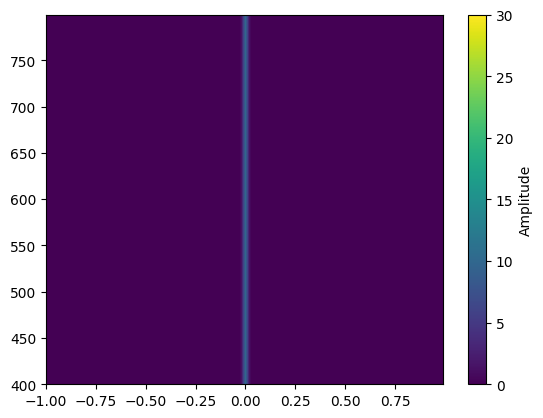

In [223]:
freq_array = jnp.arange(400,800,(800-400)/(1024/2), dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(-1,1,(1-(-1))/200, dtype=jnp.float32)[None, :] # (1,ntime), s

sigma_noise_array = jnp.asarray(freq_array, dtype=jnp.float32)[:, None]

data_array = frb_forward_model(params_list, freq_array, time_array);

plt.imshow(
    data_array,
    aspect='auto',
    origin='lower',
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30)

plt.colorbar(label="Amplitude")


In [224]:
data_array.shape[0]*data_array.shape[1]

102400

In [225]:
jax.local_device_count()

4

In [226]:
len(params_list)

1

In [227]:
kernel = NUTS(numpyro_model, dense_mass=True)
seed = 1
rng_key = jrand.PRNGKey(seed)
mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=4, chain_method="parallel" )
mcmc.run(rng_key=rng_key, data=data_array, freq_array=freq_array, time_array=time_array, sigma_noise = 20, n_pulses=len(params_list))
samples = mcmc.get_samples()

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


Running chain 1:   0%|          | 0/1000 [00:02<?, ?it/s]

Running chain 2:   0%|          | 0/1000 [00:02<?, ?it/s]


Running chain 0:   5%|▌         | 50/1000 [00:12<03:05,  5.13it/s]


Running chain 3:   5%|▌         | 50/1000 [00:12<03:16,  4.83it/s]

Running chain 1:   5%|▌         | 50/1000 [00:14<03:41,  4.29it/s]


Running chain 1:  10%|█         | 100/1000 [00:26<03:41,  4.06it/s]


Running chain 3:  15%|█▌        | 150/1000 [00:27<02:04,  6.85it/s]


Running chain 3:  20%|██        | 200/1000 [00:28<01:14, 10.80it/s]


Running chain 1:  15%|█▌        | 150/1000 [00:28<02:08,  6.60it/s]


Running chain 0:  20%|██        | 200/1000 [00:29<01:18, 10.25it/s]


Running chain 0:  25%|██▌       | 250/1000 [00:29<00:48, 15.37it/s]


Running chain 1:  25%|██▌       | 250/1000 [00:29<00:48, 

In [228]:
mcmc_data = az.from_numpyro(mcmc)

In [229]:
az.summary(mcmc_data, round_to=3)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
DM_0,-0.005,0.222,-0.430,0.449,0.004,0.006,2869.585,1240.461,1.003
alpha_0,0.988,0.037,0.913,1.051,0.001,0.001,2075.093,1567.387,1.003
beta_0,-0.048,0.555,-0.978,0.847,0.011,0.009,2195.141,1197.022,1.001
delta_0,-3.984,0.284,-4.428,-3.505,0.007,0.005,1231.555,885.989,1.004
epsilon_0,-2.019,0.055,-2.100,-1.923,0.001,0.001,1810.863,1460.239,1.001
gamma_0,0.007,0.355,-0.661,0.676,0.008,0.007,1923.809,1442.492,1.000
sigma_0,0.010,0.001,0.008,0.012,0.000,0.000,1717.520,1496.779,1.000
t0_0,0.000,0.001,-0.002,0.002,0.000,0.000,2188.170,1562.118,1.000


In [230]:
true_vals = {
    "DM_0": params_dict["DM"],
    "t0_0": params_dict["mean_arrival_time"],
    "sigma_0": params_dict["sigma"],
    "alpha_0": params_dict["alpha"],
    "DM_1": params_dict_2["DM"],
    "t0_1": params_dict_2["mean_arrival_time"],
    "sigma_1": params_dict_2["sigma"],
    "alpha_1": params_dict_2["alpha"],
}

axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0","DM_1", "t0_1", "sigma_1", "alpha_1"]);

for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0","DM_1", "t0_1", "sigma_1", "alpha_1"]):
    # posterior panel only
    axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

NameError: name 'params_dict_2' is not defined

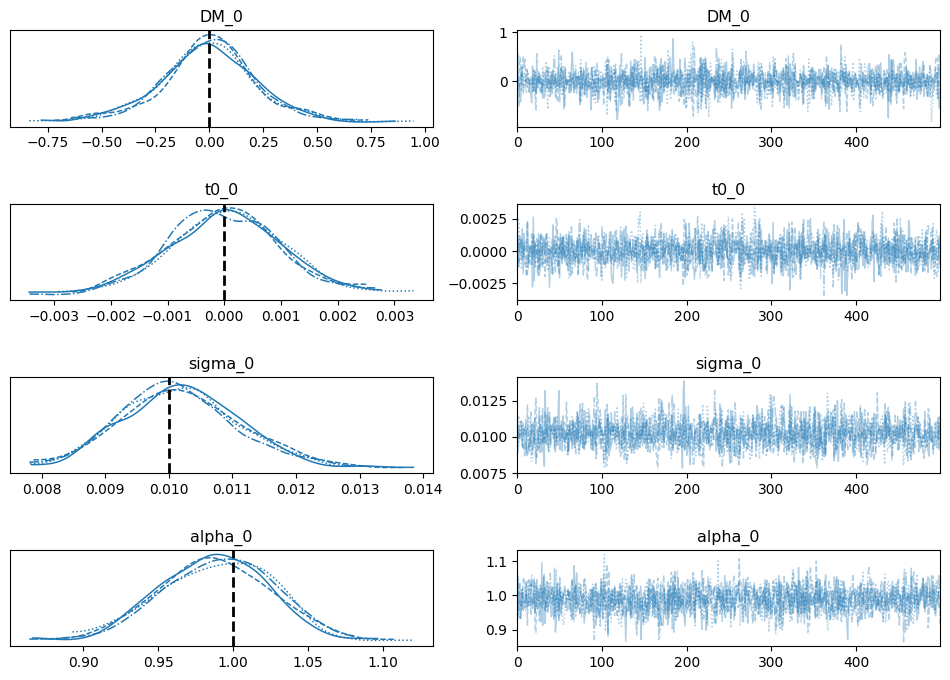

In [231]:
true_vals = {
    "DM_0": params_dict["DM"],
    "t0_0": params_dict["mean_arrival_time"],
    "sigma_0": params_dict["sigma"],
    "alpha_0": params_dict["alpha"]
}

axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0"]);

for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0"]):
    # posterior panel only
    axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

In [232]:
jax.device_count()

4

In [233]:
os.cpu_count()

64

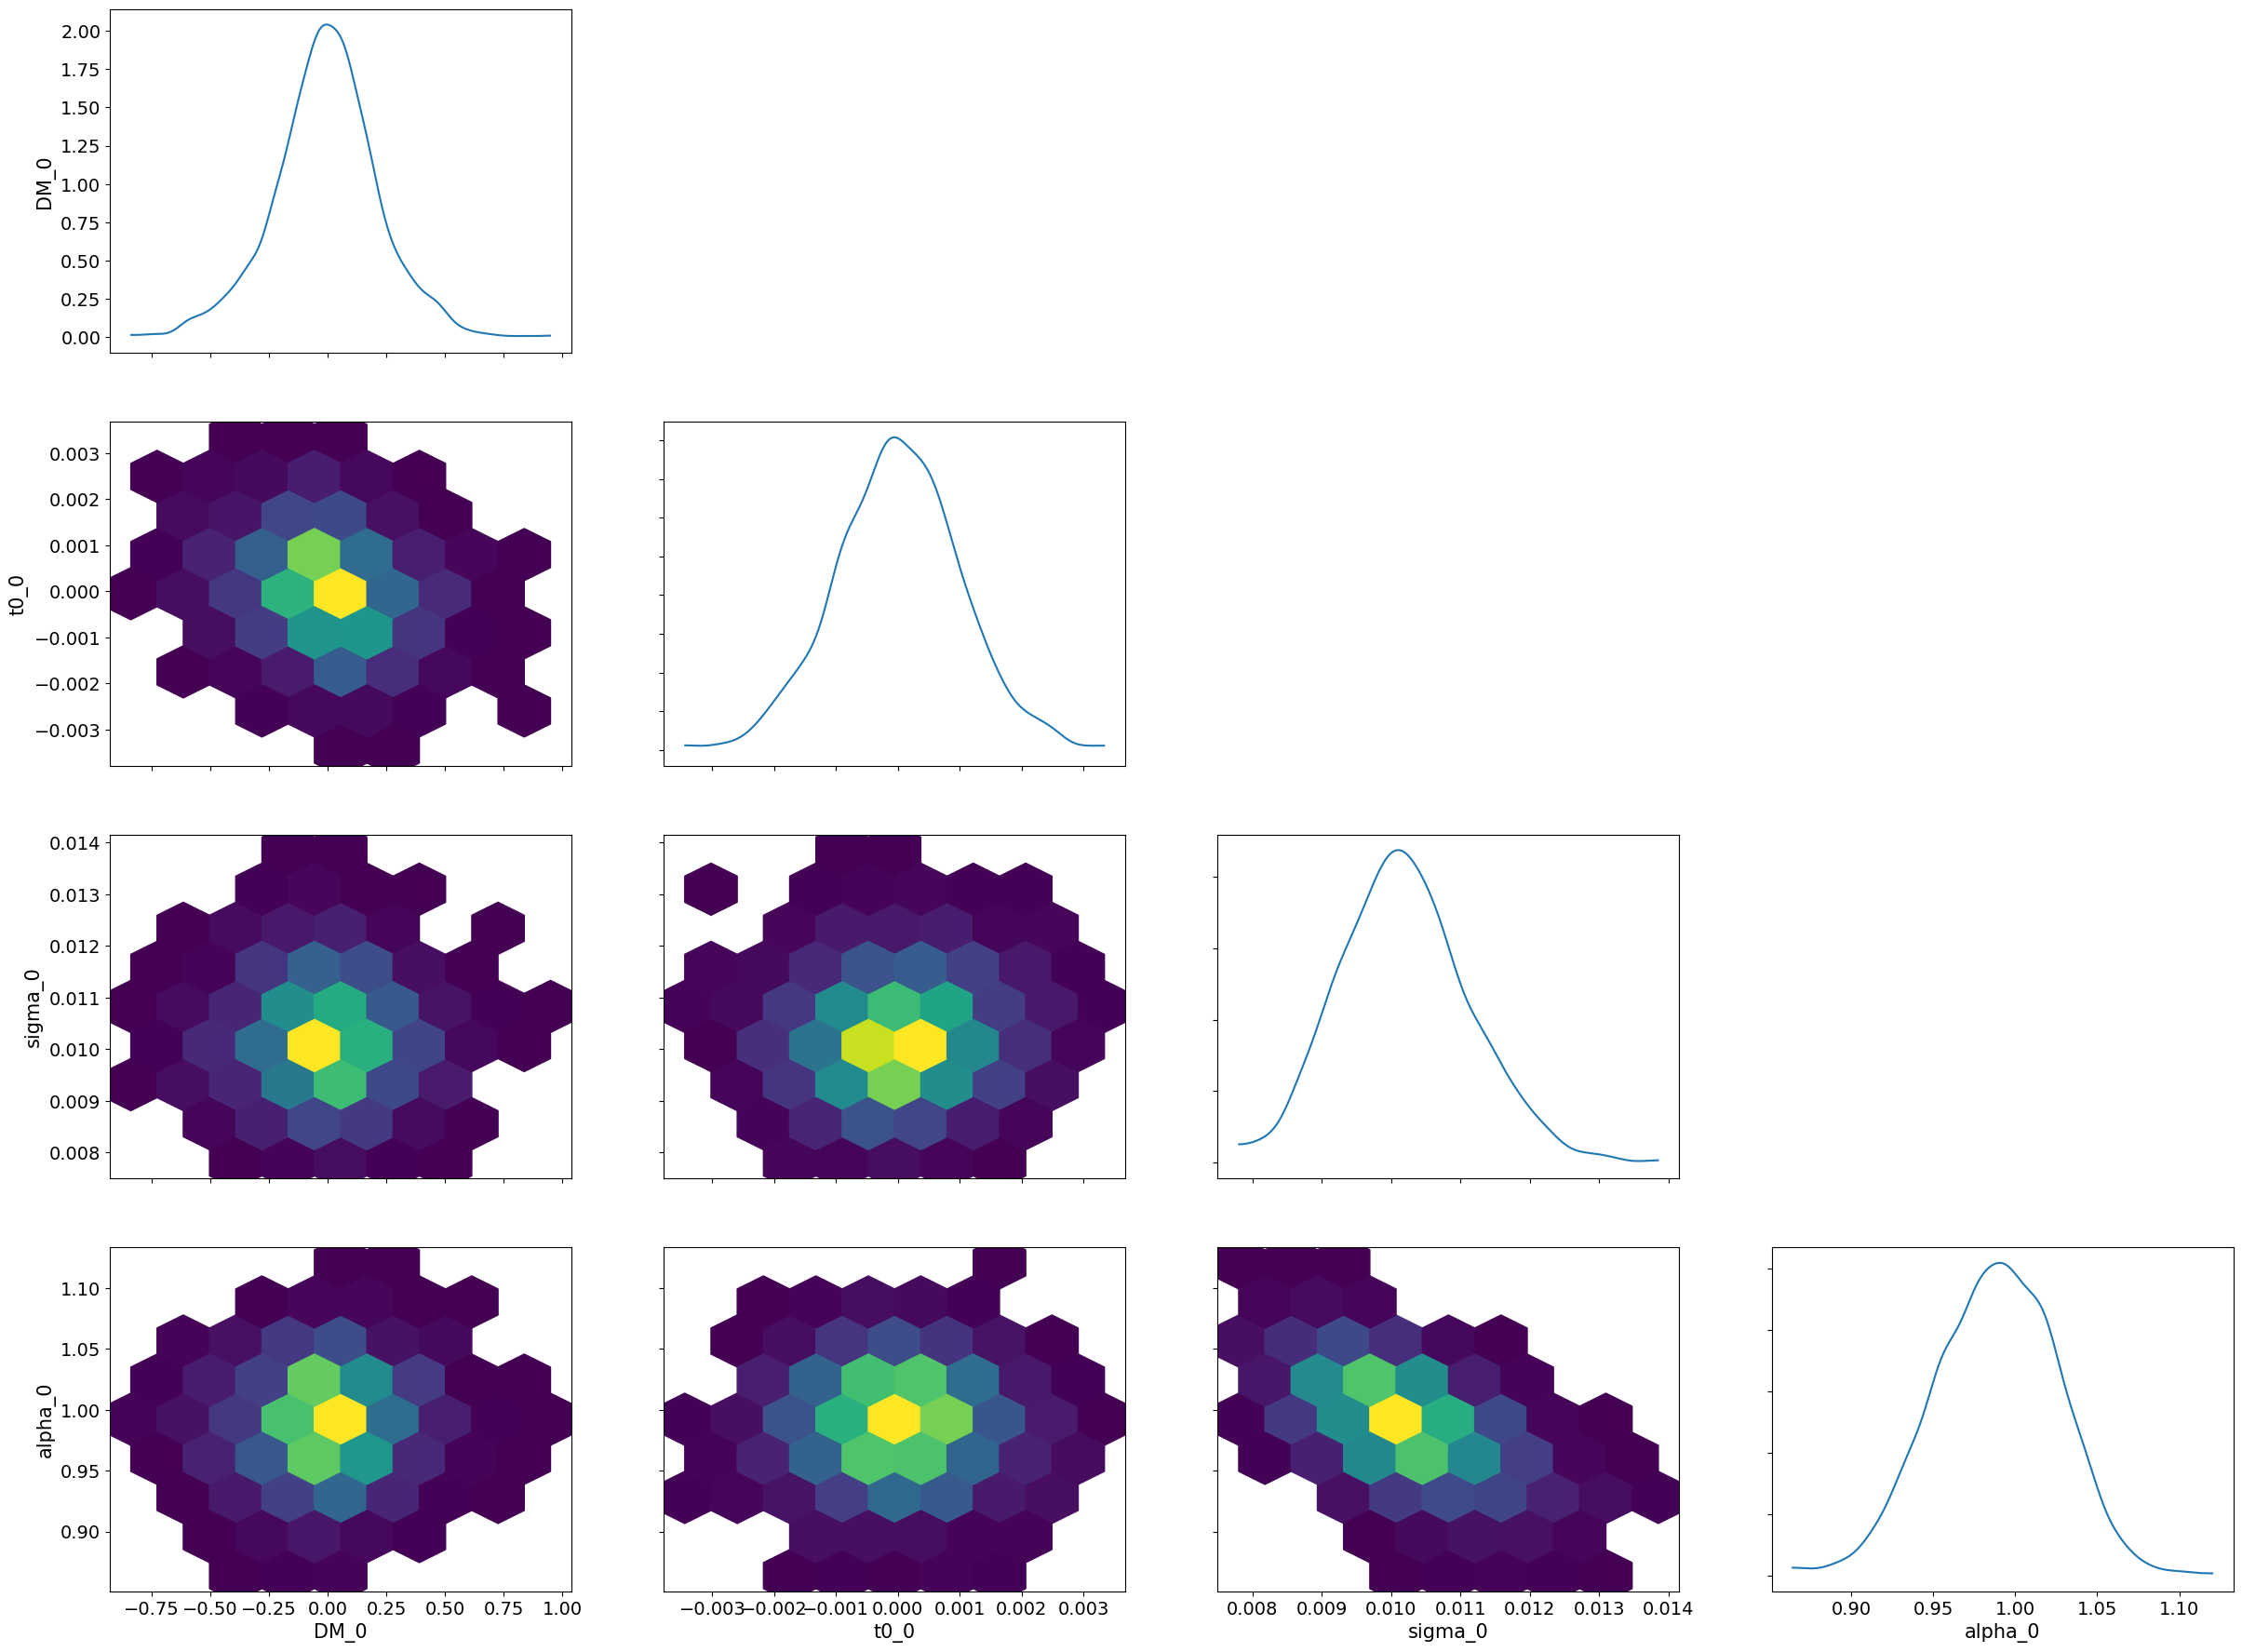

In [234]:
az.plot_pair(
    mcmc_data,
    var_names=["DM_0", "t0_0", "sigma_0", "alpha_0" ],#, "DM_1", "t0_1", "sigma_1", "alpha_1"],
    kind="hexbin",
    marginals=True
);

### Real data

#### Pulling the data

In [235]:
import numpy as np
import seaborn as sns

ModuleNotFoundError: No module named 'seaborn'

In [236]:
filename = "FRB20180730A_stokesi_dynamic_spectrum.h5"

with h5py.File(filename, "r") as handler:

    print(handler.attrs.keys())
    
    event_id = handler.attrs["event_id"]
    freq = handler["index_map"]["freqs"][:]
    
    toa = json.loads(handler.attrs["burst_parameters_json"])["arrival_time"]
    time = (handler["index_map"]["times"][:] - np.mean(toa)) * 1e3

    good_freq = handler["good_freq"][:]
    flag = handler["flag"][:]
        
    data = handler["data"][:]
    
    print(handler.attrs["burst_parameters_json"])

<KeysViewHDF5 ['beam_number', 'burst_parameters_json', 'catalog', 'center_time', 'contact', 'creator', 'datatype', 'dm_const', 'dm_incoherent', 'dm_index', 'doi', 'event_id', 'freqs_bin0', 'instrument', 'is_dedispersed', 'num_freq', 'num_time', 'pipeline_parameters_json', 'pulse_emission_region', 'ref_freq', 'repeater_name', 'res_freq', 'res_time', 'start_time_unix_nano', 'stokes', 'telescope', 'times_bin0', 'tns_name', 'unwindowed_num_time', 'unwindowed_times_bin0']>
{"amplitude": [-1.6610962224298984], "arrival_time": [482488.48689058475], "burst_width": [0.0004128824360633611], "dm": [848.8783200451409], "dm_index": [-2.0], "scattering_timescale": [0.01009891957302962], "scattering_index": [-4.0], "spectral_index": [2.078152594885448], "spectral_running": [-7.62940918595922], "ref_freq": [400.1953125]}


#### Downsampling data

In [237]:
def bin_freq_channels(data, fbin_factor=4):
    num_chan = data.shape[0]
    if num_chan % fbin_factor != 0:
        raise ValueError("frequency binning factor `fbin_factor` should be even")
    data = np.nanmean(data.reshape((num_chan // fbin_factor, fbin_factor) + data.shape[1:]), axis=1)
    return data


def bin_freq_boolean(arr, fbin_factor=4):
    n = arr.shape[0]
    if n % fbin_factor != 0:
        raise ValueError("frequency binning factor must divide number of channels")

    arr = arr.reshape((n // fbin_factor, fbin_factor) + arr.shape[1:])
    return np.any(arr, axis=1)

binning_factor = 2**4
flag = bin_freq_boolean(flag, fbin_factor=binning_factor)
good_freq = bin_freq_boolean(good_freq, fbin_factor=binning_factor)
data = bin_freq_channels(data, fbin_factor=binning_factor)

combined_flag = flag & good_freq[:, jnp.newaxis]

Downsampling gives us a mask of bad frequencies, we'll apply the mask directly to the data to remove masked frequencies before analyzing. The model will also be passed an array of masked frequency values.

In [238]:
freq_array = jnp.arange(freq[0],freq[-1],(freq[-1]-freq[0])/data.shape[0], dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
freq_array_reshaped = freq_array[good_freq]

time_array = jnp.arange(time[0],time[-1],(time[-1]-time[0])/data.shape[1], dtype=jnp.float32)[None, :]  # (1,ntime), s

data_reshaped = data[combined_flag].reshape(freq_array_reshaped.shape[0],time_array.shape[1])

First plotting data with masked channels included
Then plotting data with masked channels removed


Text(0, 0.5, 'Frequency [MHz]')

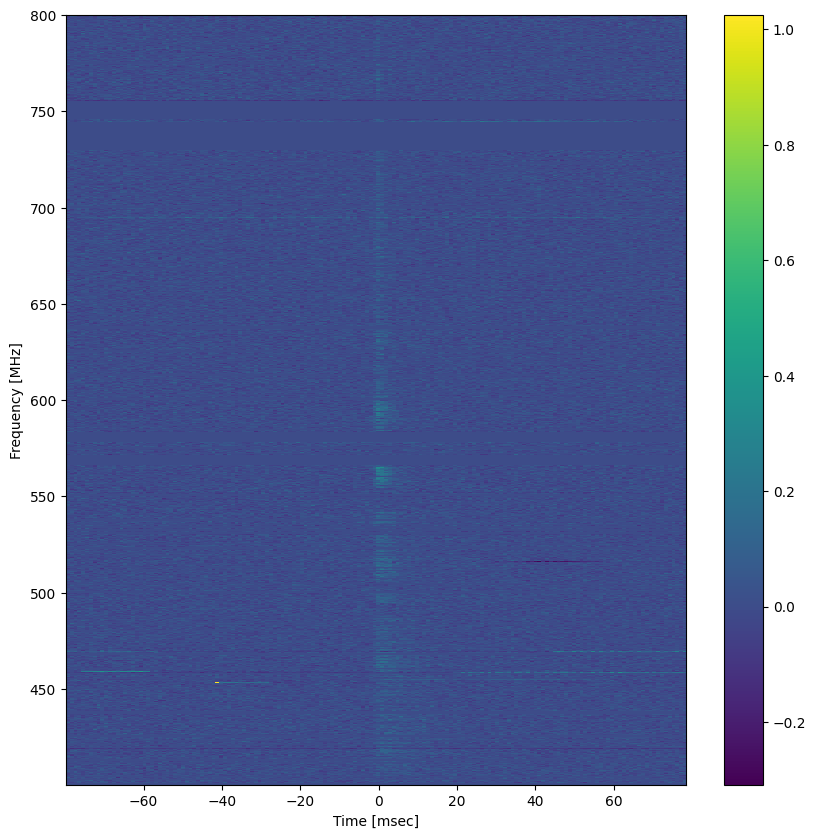

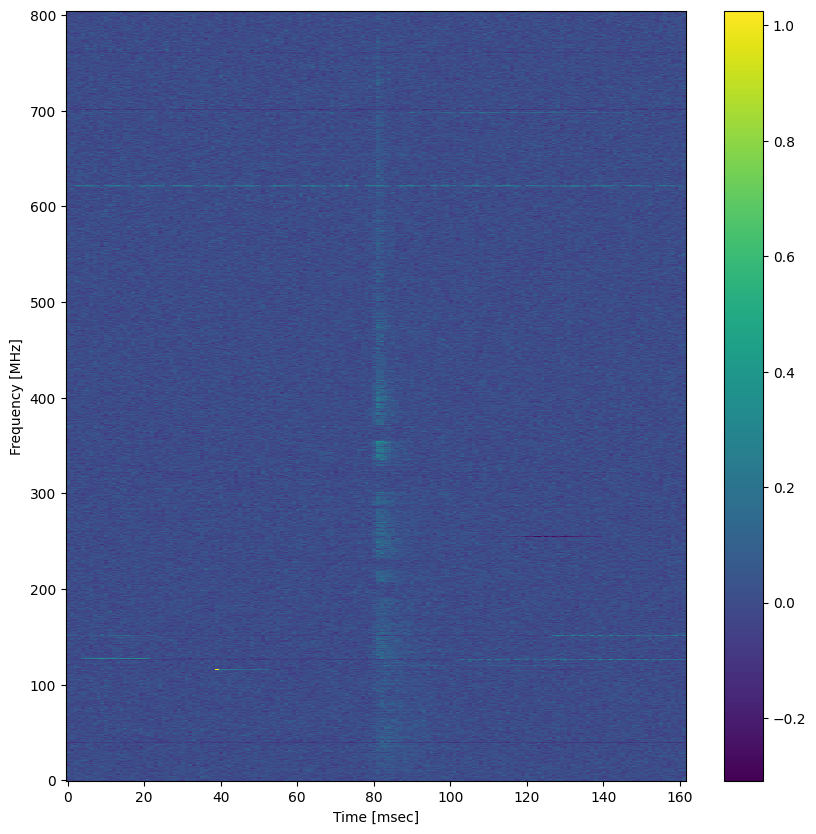

In [239]:
print("First plotting data with masked channels included")

fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data * combined_flag,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

print("Then plotting data with masked channels removed")

fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data_reshaped,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest")
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

#### Estimating noise

In [240]:
times_noise = jnp.asarray([i for i in time_array[0] if i<-10]).flatten()
len(times_noise)

72

Noise segments we will draw from


Text(0, 0.5, 'Frequency [MHz]')

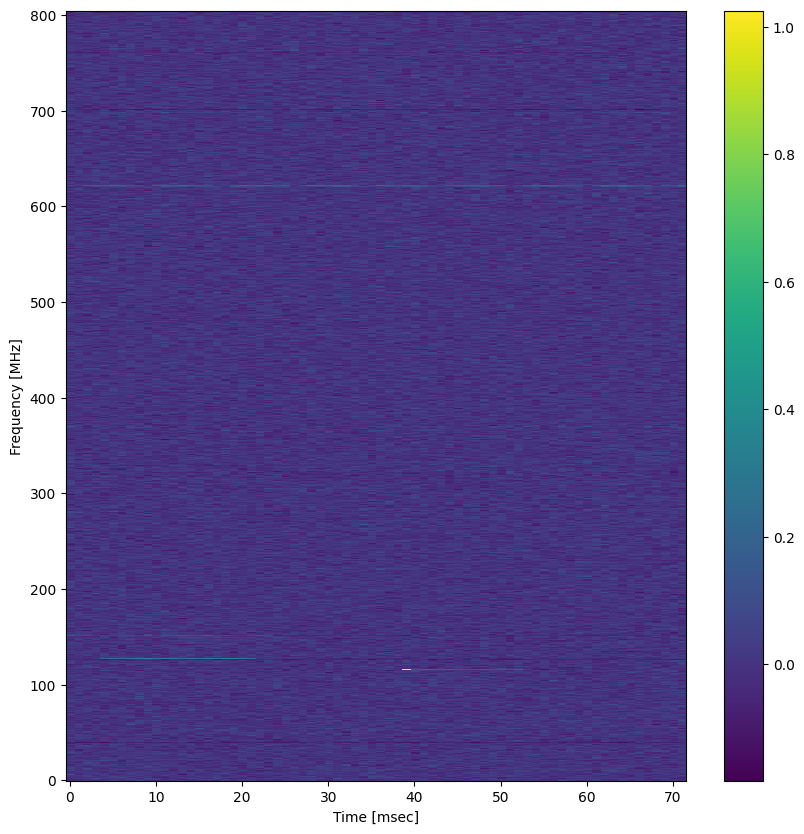

In [246]:
print("Noise segments we will draw from")
fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data_reshaped[:,0:len(times_noise)],
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest")
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

In [247]:
data_reshaped[:,0:len(times_noise)]
noise_median_estimates = jnp.asarray([jnp.median(data_reshaped[i,0:len(times_noise)]) for i in jnp.arange(len(freq_array_reshaped))])[:,None]
                                     

(array([  3.,   1.,  23., 766.,  10.,   0.,   1.,   0.,   0.,   1.]),
 array([-0.08491646, -0.06033602, -0.03575559, -0.01117516,  0.01340527,
         0.0379857 ,  0.06256613,  0.08714657,  0.111727  ,  0.13630743,
         0.16088787]),
 <BarContainer object of 10 artists>)

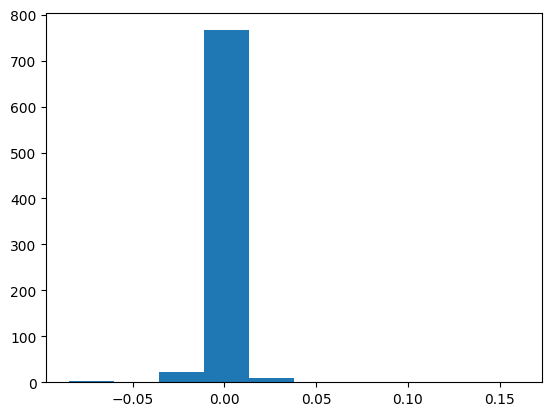

In [248]:
plt.hist(noise_median_estimates)

#### Running model

In [253]:
kernel = NUTS(numpyro_model, dense_mass=True)
seed = 1
rng_key = jrand.PRNGKey(seed)
mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=4, chain_method="parallel" )
mcmc.run(rng_key=rng_key, data=data_reshaped, freq_array=freq_array_reshaped, time_array=time_array, sigma_noise = noise_median_estimates, n_pulses=1)
samples = mcmc.get_samples()

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


Running chain 1:   0%|          | 0/1000 [00:03<?, ?it/s]

Running chain 2:   0%|          | 0/1000 [00:03<?, ?it/s]


Running chain 1:  15%|█▌        | 150/1000 [00:03<00:00, 1047.97it/s]

Running chain 2:  15%|█▌        | 150/1000 [00:03<00:00, 1225.37it/s]


Running chain 1:  30%|███       | 300/1000 [00:03<00:00, 1062.55it/s]

Running chain 2:  30%|███       | 300/1000 [00:03<00:00, 1229.82it/s]


Running chain 0:  45%|████▌     | 450/1000 [00:03<00:00, 1237.83it/s]


Running chain 3:  35%|███▌      | 350/1000 [00:03<00:00, 957.10it/s]

Running chain 0:  60%|██████    | 600/1000 [00:03<00:00, 1229.78it/s]


Running chain 3:  45%|████▌     | 450/1000 [00:03<00:00, 931.75it/s]

Running chain 0:  75%|███████▌  | 750/1000 [00:03<00:00, 1235.38it/s]


Running chain 3:  60%|██████    | 600/100

In [254]:
mcmc_data = az.from_numpyro(mcmc)

Running chain 1: 100%|██████████| 1000/1000 [00:04<00:00, 246.79it/s]



Running chain 3: 100%|██████████| 1000/1000 [00:04<00:00, 241.97it/s]


In [255]:
az.summary(mcmc_data, round_to=3)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
DM_0,-26.433,51.510,-74.775,49.837,25.548,9.567,4.065,4.065,5.563132e+15
alpha_0,0.810,0.388,0.575,1.482,0.192,0.111,4.065,4.065,5.563132e+15
beta_0,-0.112,0.494,-0.575,0.689,0.245,0.121,4.065,4.065,5.867876e+15
delta_0,-4.045,0.317,-4.373,-3.728,0.157,0.004,4.065,4.065,5.563132e+15
epsilon_0,-2.000,0.034,-2.029,-1.941,0.017,0.010,4.065,4.065,5.867876e+15
gamma_0,-0.673,1.282,-2.123,1.396,0.636,0.334,4.065,4.065,5.867876e+15
sigma_0,0.065,0.017,0.047,0.083,0.008,0.001,4.065,4.065,5.563132e+15
t0_0,0.020,0.037,-0.039,0.061,0.018,0.010,4.065,4.065,5.867876e+15


/mnt/home/hsiegel/frb_bayesian_analysis/.venv/lib/python3.11/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")
/mnt/home/hsiegel/frb_bayesian_analysis/.venv/lib/python3.11/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")
/mnt/home/hsiegel/frb_bayesian_analysis/.venv/lib/python3.11/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")
/mnt/home/hsiegel/frb_bayesian_analysis/.venv/lib/python3.11/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data a

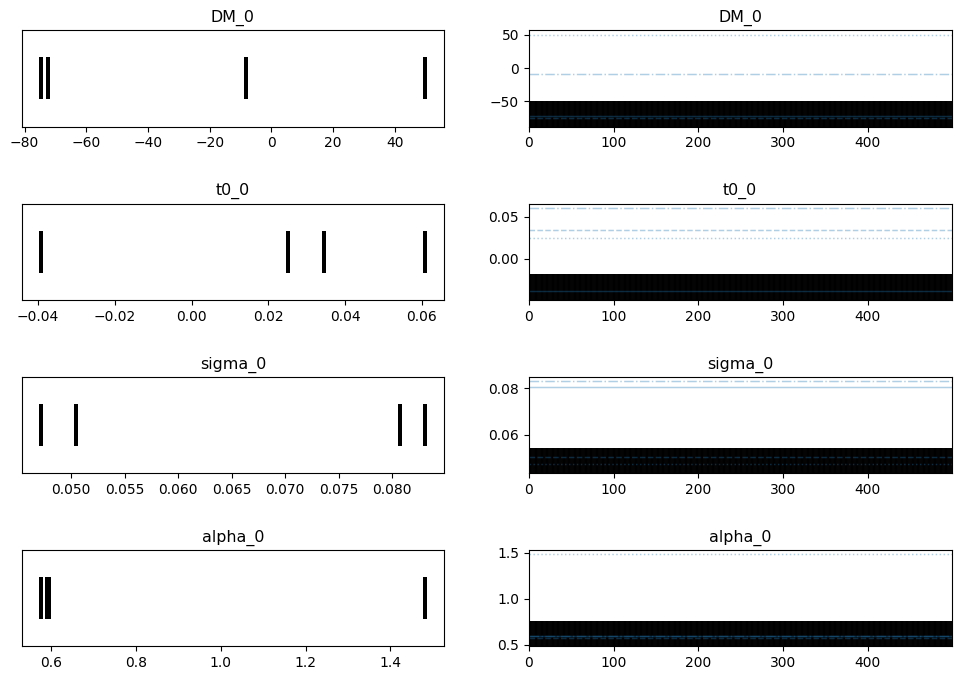

In [256]:
axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0"]);

# for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0"]):
#     # posterior panel only
#     axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

## New model with slice (did not work well, possibly due to NUTS gradients breaking with changing boundaries of slice for model)

In [187]:
def loglikelihood(data, params_dict, freqs,times, normalized_freqs, sigma_noise, det_response=jnp.float32(1)):
    """
        Model of a single pulse, which will be summed in the forward model for multi-pulse signals.
        
        params_dict: dict of each parameter of the pulse
        freqs: array of frequency bins in the data
        times: array of time bins in the data
        model_template: an empty array of dimensions (nfreq, ntime) that will be a fixed data structure for model values to be put into, saves us from having to generate this for every call of this function and also allows us to slice out trivial model elements which equate to zero
    """

    # frequency array nu_k
    # shape of (nfreq,1), units of MHz, these are the rows of the model matrix
    # freqs = jnp.asarray(freq_array, dtype=jnp.float32)[:, None]
    
    # time array t_n
    # shape of (1,ntime), units of seconds, these are the columns of the model matrix
    # times = jnp.asarray(time_array, dtype=jnp.float32)[None, :]

    #params

    #det_response = jnp.float32(1) # TO-DO: WILL BE FUNCTION LATER !!!! Maybe also convolution is involved if frequencies are not independent between channels
    
    freq_ref = jnp.float32(params_dict["freq_ref"]) # fixed reference / pivot EM frequency nu_r, set approximately equal to frequency of peak emission for a pulse with Gaussian-like SED in the dynamic spectrum element D_kn
    tau_ref = jnp.float32(params_dict["tau_ref"]) # fixed scatter broadening timescale at freq_ref; if 0, no scatter is put in the model
    
    alpha = jnp.float32(params_dict["alpha"]) # Base-10 exponent of amplitude for burst componnent
    gamma = jnp.float32(params_dict["gamma"]) # Spectral index for burst component
    beta = jnp.float32(params_dict["beta"]) # Spectral running for burst component

    delta = jnp.float32(params_dict["delta"]) # Exponent of frequency dependence for scatter-broadening
    epsilon = jnp.float32(params_dict["epsilon"]) # Exponent of frequency dependence for pulse dispersion
    mean_arrival_time = jnp.float32(params_dict["mean_arrival_time"]) # defined so that the pulse peaks at freq_ref at this time (before scatter or dispersion shifts at other frequencies)
    sigma = jnp.float32(params_dict["sigma"])
    
    DM = jnp.float32(params_dict["DM"]) # dispersion measure, pc/cm^3
    #k_DM = jnp.float32(params_dict.get("k_DM",(2.41*1e-4)**(-1)))# dispersion constant, (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    k_DM = jnp.float32(params_dict["k_DM"])# dispersion constant, (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
        
    # model M_{kn}= ( A * F_k * T_kn)
    # A : global amplitude
    # F : frequency-dependent spectral energy distribution (SED)
    # T : dispersed temporal shape of pulse

    A = 10**alpha
    #print(A)

    kappa = gamma + ( beta*jnp.log(normalized_freqs) )#Running power law of SED
    F = normalized_freqs**kappa * det_response
    #print(F)

    mean_time_gaussian = mean_arrival_time + ( k_DM * DM * ( (freqs**epsilon) - (freq_ref**epsilon) ) ) #mean time in the gaussian model with no scatter broadening
    # return mean_time_gaussian
    
    taus = tau_ref * (normalized_freqs**delta) # Timescale of scattering-broadening at nu_k
    dispersed_times = (times - mean_time_gaussian) #dispersed timeseries wrt first time stamp
    #print(mean_time_gaussian-5*sigma)

    #TO-DO: rewrite as jnp.select instead of if else
    
    # if tau_ref !=0: #scatter broadening
    #     T = ((1/taus) * 0.5) * jnp.exp( (sigma**2) / (2 * taus**2) - (dispersed_times/taus) ) * (1 + jscipy.special.erf((dispersed_times - sigma*sigma/taus)/(jnp.sqrt(2) * sigma)))
    # else: #no scatter broadening
    cutoff_array = jnp.ones(freqs.shape[0], dtype=jnp.float32)*(5*sigma)# we'll set a cutoff beyond which no function calls are actually made because the model is sufficiently close to zero
    start_index, end_index = vmap(find_indices)(dispersed_times,-cutoff_array,cutoff_array)# find times that will give function values within our cutoff, and get indices for slicing
    col_index = jnp.arange(times.shape[1])[None, :]      # (1, ncols)
    mask = (col_index >= start_index[:, None]) & (col_index < end_index[:, None])        

    logL = jnp.sum(
        jnp.where(
            mask,
            -0.5 * ((data - A*F*jnp.exp(-0.5 * (dispersed_times / sigma)**2)) / sigma_noise)**2,
            0
        )
    )     

    return logL

In [164]:
params_dict = {
    "DM": 100.0,           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": 0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 1.0,
    "k_DM" : (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
}

# fixed / typical values
freq_ref = 600.0
gamma = 0.0
beta = 0.0
delta = -4.0
epsilon = -2.0
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(0,2,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
normalized_freqs = freq_array/freq_ref


M = (single_pulse_model(params_dict, freq_array, time_array))

L = loglikelihood(M,params_dict,freq_array,time_array,normalized_freqs,sigma_noise=20.0)

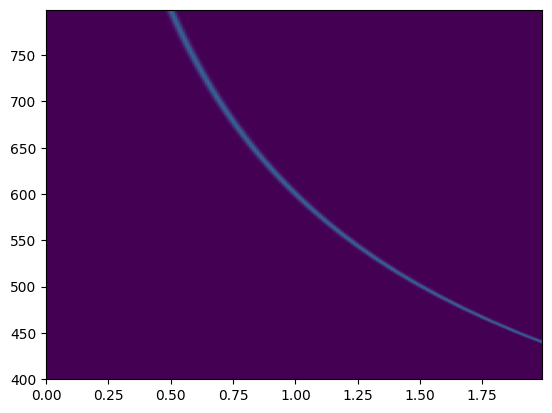

In [165]:


plt.imshow(
    M,
    aspect='auto',
    origin='lower',
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30
)

In [144]:
L

Array(0., dtype=float32)

In [188]:
def numpyro_model_sliced(data, freq_array, time_array, n_pulses=1, sigma_noise=1):

    DM = numpyro.sample(f"DM", dist.Uniform(0, 500))
    mean_arrival_time = numpyro.sample(f"t0", dist.Uniform(0.0, 2.0))
    sigma = numpyro.sample(f"sigma", dist.Uniform(0.005, 0.1))
    alpha = numpyro.sample(f"alpha", dist.Uniform(0, 2.0))
    tau_ref = 0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
    
    # fixed / typical values
    freq_ref = 600.0
    gamma = 0.0
    beta = 0.0
    delta = -4.0
    epsilon = -2.0
    k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

    params_dict = {
        "DM": DM,
        "mean_arrival_time": mean_arrival_time,
        "sigma": sigma,
        "alpha": alpha,
        "tau_ref": tau_ref,
        "freq_ref": freq_ref,
        "gamma": gamma,
        "beta": beta,
        "delta": delta,
        "epsilon": epsilon,
        "k_DM": k_DM
    }

    logL = loglikelihood(M,params_dict,freq_array,time_array,normalized_freqs,sigma_noise)
    numpyro.factor("obs", logL)

## Run new model

In [3]:
params_dict = {
    # Pulse and dispersion
    "DM": 100.0,           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": 0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 1.0,
    "k_DM" : (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
}

params_list = [params_dict]

# params_dict_2 = {
#     # Pulse and dispersion
#     "DM": 90.0,           # pc/cm^3
#     "freq_ref": 600.0,     # MHz, reference frequency near middle of band
#     "tau_ref": 0.000, # 0.015,      # s, scatter broadening at freq_ref
#     "epsilon": -2.0,        # dispersion exponent
    
#     # Temporal shape
#     "sigma": 0.01,        # s, intrinsic width of pulse
    
#     # Amplitude / spectrum
#     "alpha": 1.0,          # log10 global amplitude
#     "gamma": 0.0,         # spectral index for SED
#     "beta": 0.0,           # running spectral index
#     "delta": -4.0,          # scatter-frequency exponent
#     "mean_arrival_time": 0.95,
#     "k_DM" = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
# }

# params_list = [params_dict, params_dict_2]

In [4]:
data_array = frb_forward_model(params_list, freq_array, time_array);

plt.imshow(
    data_array,
    aspect='auto',
    origin='lower',
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30)

plt.colorbar(label="Amplitude")


NameError: name 'freq_array' is not defined

In [189]:
kernel = NUTS(numpyro_model_sliced)
seed = 1
rng_key = jrand.PRNGKey(seed)
mcmc = MCMC(kernel, num_warmup=500, num_samples=500)
mcmc.run(rng_key=rng_key, data=M, freq_array=freq_array, time_array=time_array, sigma_noise = 20, n_pulses=1)
samples = mcmc.get_samples()

sample: 100%|██████████| 1000/1000 [08:10<00:00,  2.04it/s, 1023 steps of size 7.75e-04. acc. prob=0.87]


In [190]:
mcmc_data = az.from_numpyro(mcmc)

In [196]:
az.summary(mcmc_data, round_to=3)

arviz - WARNING - Shape validation failed: input_shape: (1, 500), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
DM_3,133.230,84.655,8.708,260.564,15.568,17.396,30.439,29.604,NaN
alpha_3,0.091,0.075,0.004,0.230,0.020,0.011,6.559,40.210,NaN
sigma_3,0.014,0.008,0.005,0.030,0.003,0.001,4.815,13.252,NaN
t0_3,1.602,0.492,0.355,1.996,0.148,0.154,14.098,33.155,NaN


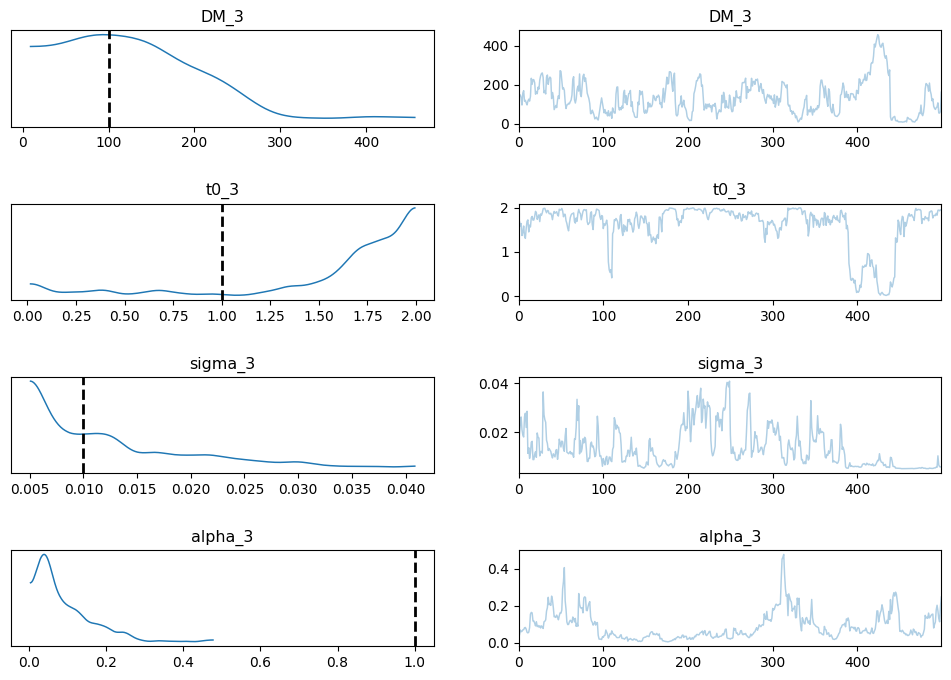

In [192]:
true_vals = {
    "DM_3": params_dict["DM"],
    "t0_3": params_dict["mean_arrival_time"],
    "sigma_3": params_dict["sigma"],
    "alpha_3": params_dict["alpha"]}
    # ,"DM_1": params_dict_2["DM"],
    # "t0_1": params_dict_2["mean_arrival_time"],
    # "sigma_1": params_dict_2["sigma"],
    # "alpha_1": params_dict_2["alpha"],
# }

axes = az.plot_trace(mcmc_data, var_names=["DM_3", "t0_3", "sigma_3", "alpha_3"]);#,"DM_1", "t0_1", "sigma_1", "alpha_1"]);

for i, var in enumerate(["DM_3", "t0_3", "sigma_3", "alpha_3"]):#,"DM_1", "t0_1", "sigma_1", "alpha_1"]):
    # posterior panel only
    axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

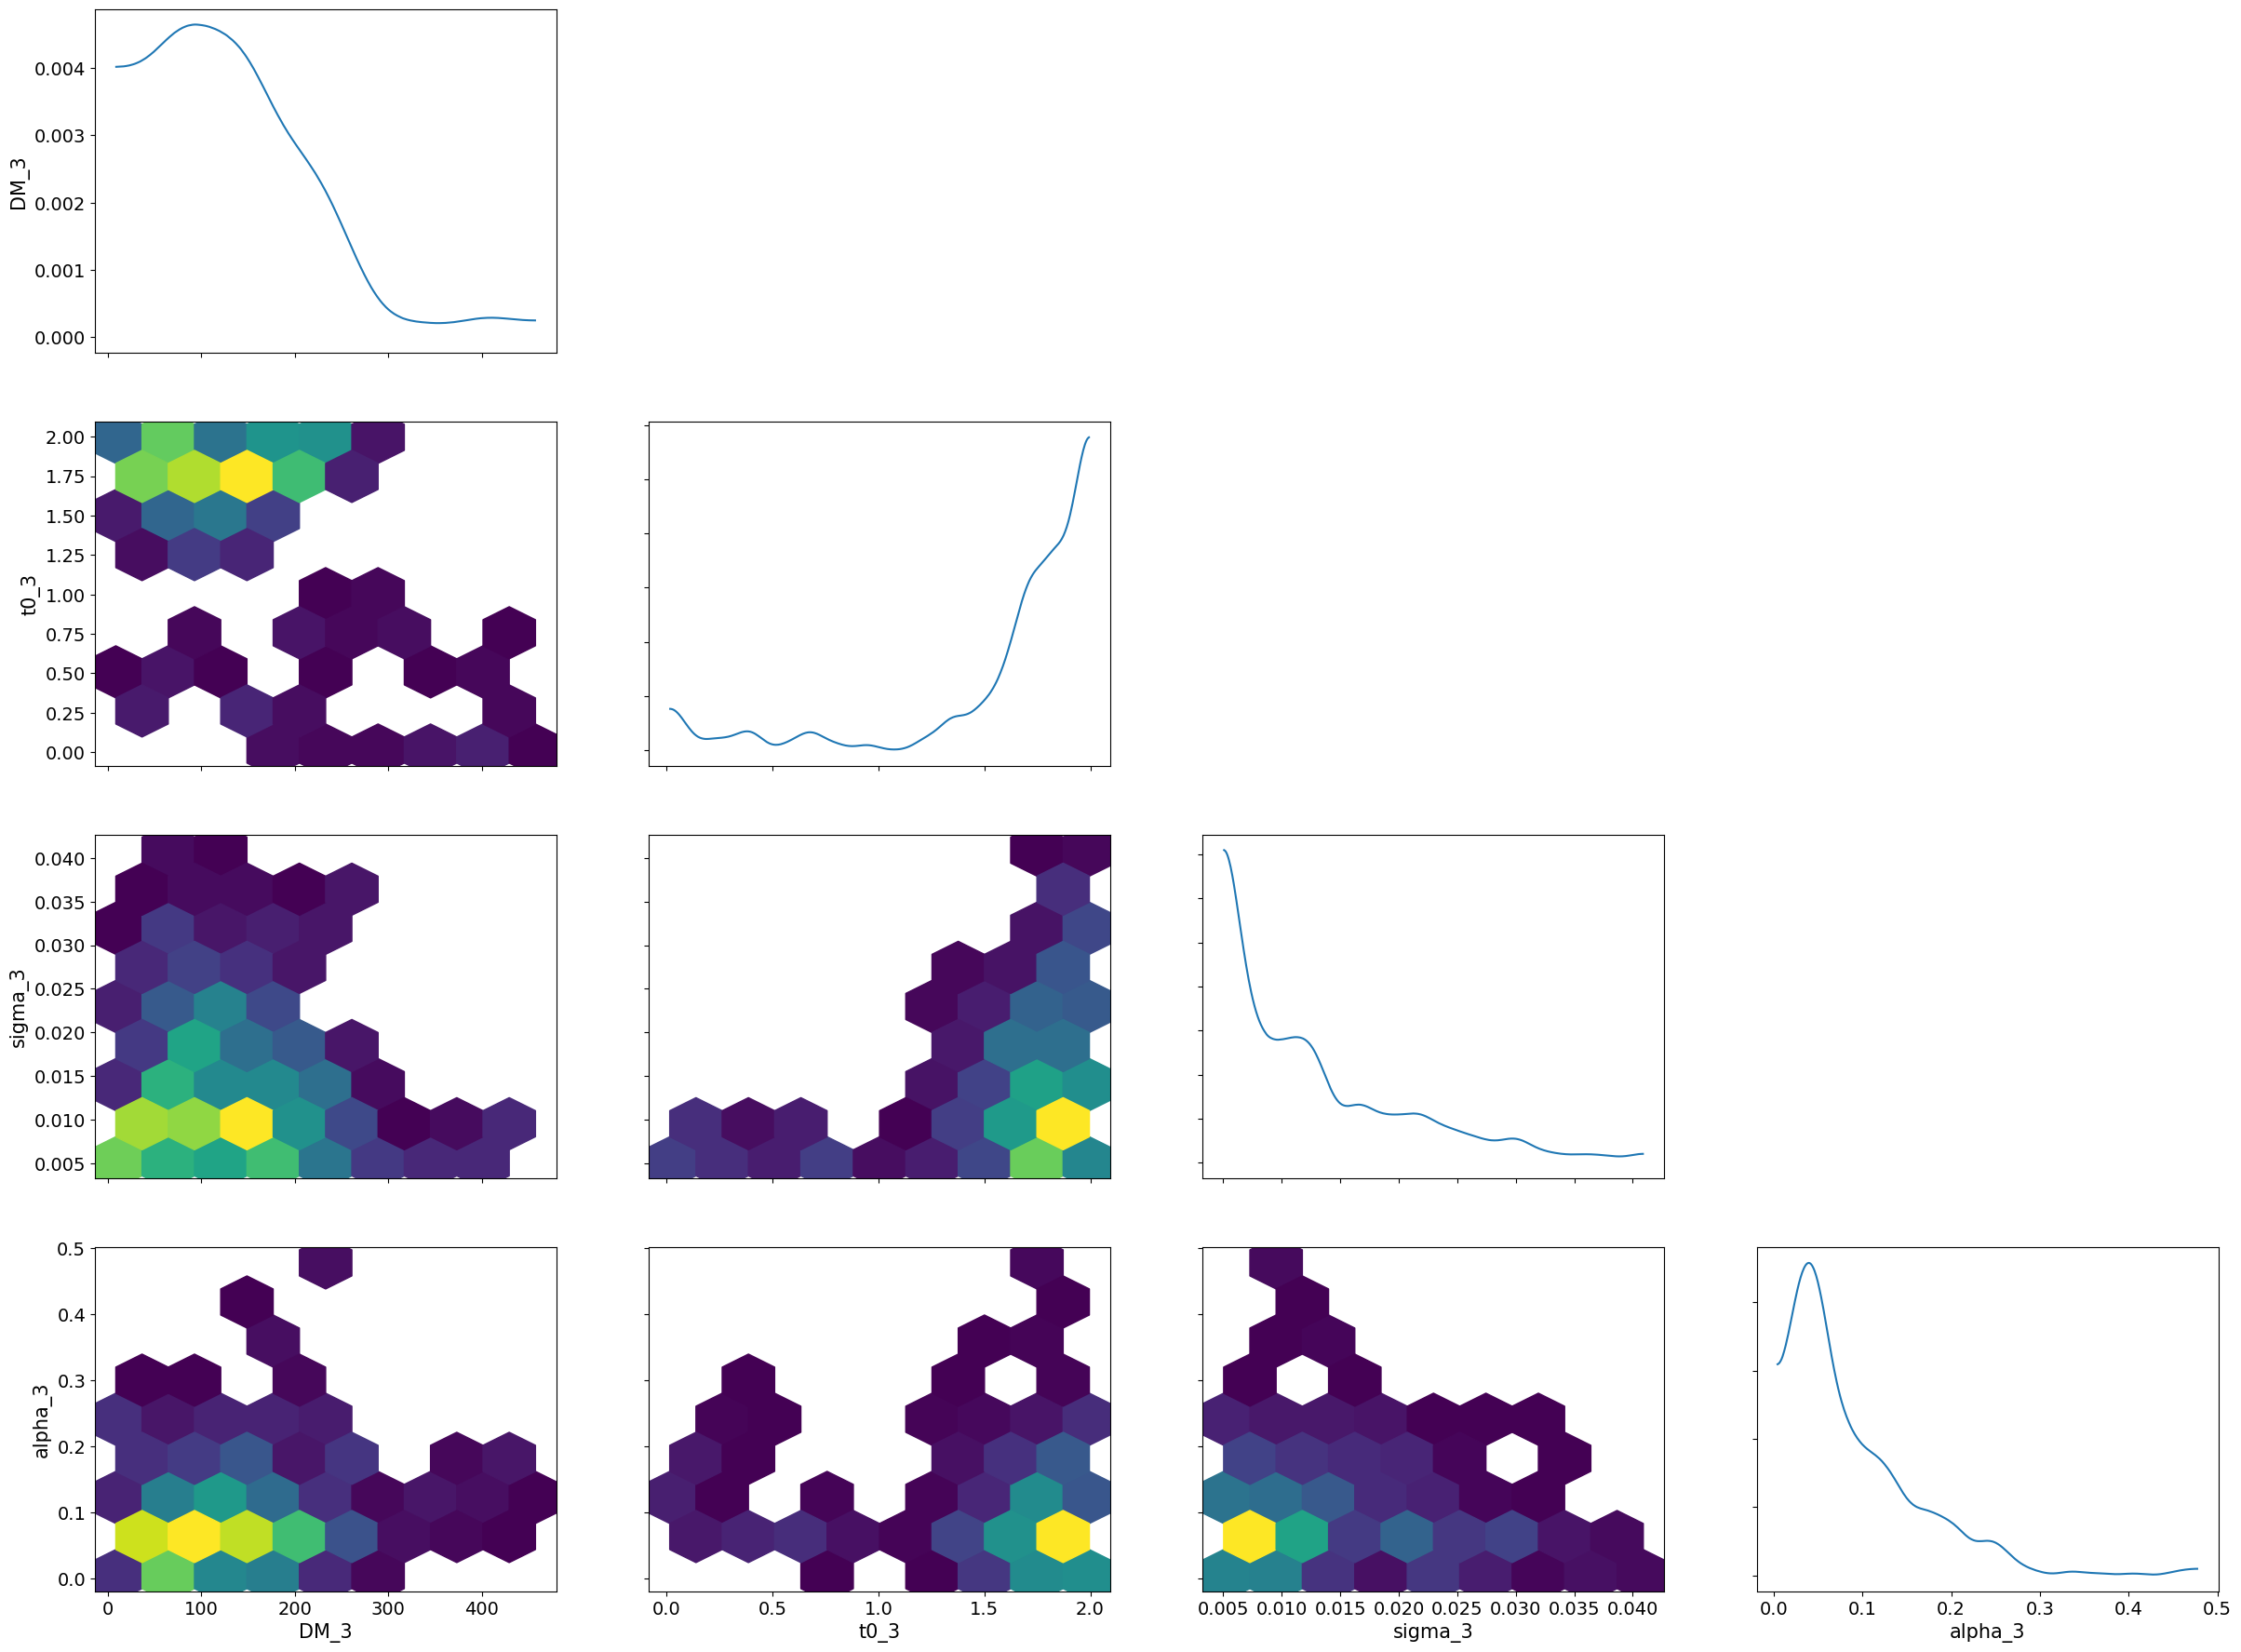

In [194]:
az.plot_pair(
    mcmc_data,
    var_names=["DM_3", "t0_3", "sigma_3", "alpha_3" ],#, "DM_1", "t0_1", "sigma_1", "alpha_1"],
    kind="hexbin",
    marginals=True
);

# Simpulse

In [24]:
import simpulse
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [25]:
def make_plot(sp, ifreq_list, color_list, label_list):

    # check whether inputs are valid objects
    assert isinstance(sp, simpulse.single_pulse)
    assert len(ifreq_list) == len(color_list) == len(label_list)

    # given sp, get the end points of the time axis
    (plot_t0, plot_t1) = sp.get_endpoints()

    # loop over various plot types, e.g., with(out) labels
    for (plot_nt, ls, lflag) in [ (100,'-',True), (1000,':',False) ]:
        
        # make an empty array of (freq, time)
        ts = np.zeros((sp.nfreq, plot_nt))
        
        # add the pulse to the array, constrained by the end points
        sp.add_to_timestream(ts, plot_t0, plot_t1)

        # initialize empty vectors for holding plot data
        # upsample by 2 for a histogram look
        x = np.zeros(2*plot_nt)
        y = np.zeros(2*plot_nt)
        
        # assign time values
        t = np.linspace(plot_t0, plot_t1, plot_nt+1)
        x[0::2] = t[:-1]
        x[1::2] = t[1:]
        
        # looping over a set of freq channels, assign freq values to the y-axis vector
        for (ifreq, color, label) in zip(ifreq_list, color_list, label_list):
            
            #ISSUE: making the code more general, maybe ifreq need not to be an integer?
            y[0::2] = ts[ifreq,:]
            y[1::2] = ts[ifreq,:]
        
            # choose a good font
            font = {'family':'serif', 'size': 14}
            matplotlib.rc('font', **font)
            
            # plot with(out) label
            if lflag:
                plt.plot(x, y, color=color, ls=ls, label=label)
            else:
                plt.plot(x, y, color=color, ls=ls)

    plt.legend(loc='upper right').draw_frame(False)
    plt.show()
    # plt.savefig(filename)
    # plt.clf()
    # print 'wrote', filename

In [9]:
pulse_nt = 1024
nfreq = 512
freq_lo_MHz = 1000.0
freq_hi_MHz = 2000.0
dm = 10.0
sm = 4.0
intrinsic_width = 0.0
fluence = 30.0
spectral_index = 0.0
undispersed_arrival_time = 0.100

In [ ]:
simpulse.single_pulse

In [10]:
sp = simpulse.single_pulse(pulse_nt, nfreq, freq_lo_MHz, freq_hi_MHz, dm, sm, intrinsic_width, fluence, spectral_index, undispersed_arrival_time)

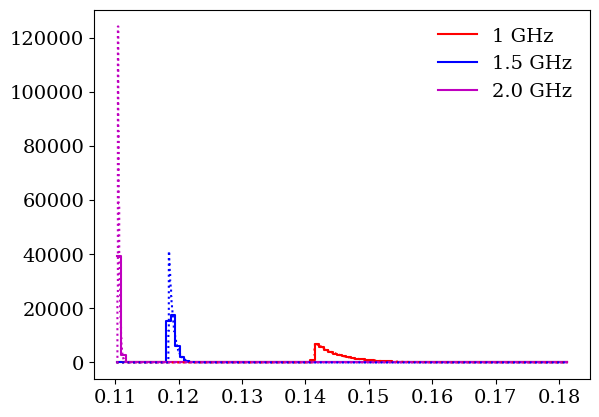

In [11]:
make_plot(sp, 
          ifreq_list = [0, 256, 511], 
          color_list = ['r', 'b', 'm'],
          label_list = [ '1 GHz', '1.5 GHz', '2.0 GHz' 

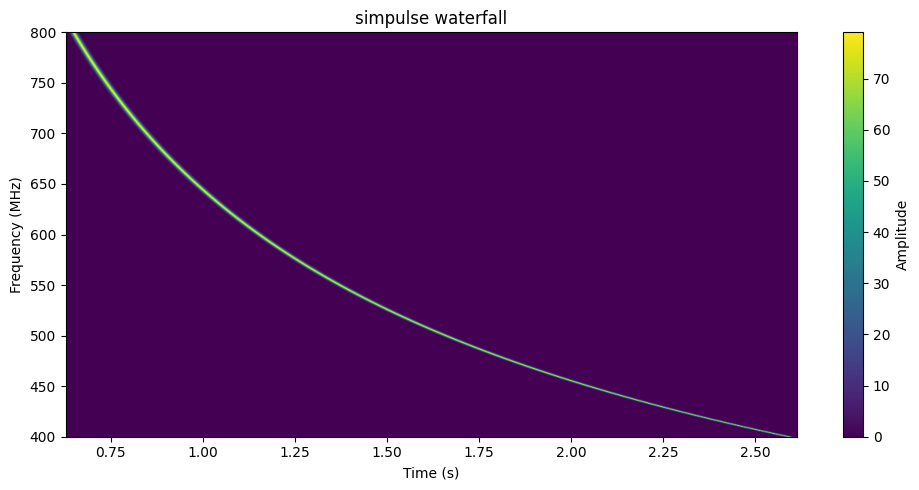

In [26]:
# ----------------------------
# 1. Define pulse parameters
# ----------------------------

pulse_nt = 1024
nfreq = 512
freq_lo_MHz = 400.0       # CHIME band
freq_hi_MHz = 800.0
dm = 100.0                # pc/cm^3
sm = 0.0                  # scattering measure
intrinsic_width = 5e-3    # s
fluence = 1.0             # arbitrary units
spectral_index = 0.0
undispersed_arrival_time = 0.  # s

# ----------------------------
# 2. Create the pulse
# ----------------------------

sp = simpulse.single_pulse(
    pulse_nt,
    nfreq,
    freq_lo_MHz,
    freq_hi_MHz,
    dm,
    sm,
    intrinsic_width,
    fluence,
    spectral_index,
    undispersed_arrival_time
)

# ----------------------------
# 3. Allocate timestream
# ----------------------------

ts = np.zeros((nfreq, pulse_nt))
plot_t0, plot_t1 = sp.get_endpoints()
sp.add_to_timestream(ts, plot_t0, plot_t1)

# ----------------------------
# 4. Compute frequency axis in MHz
# ----------------------------

freqs_MHz = np.linspace(freq_lo_MHz, freq_hi_MHz, nfreq)

# ----------------------------
# 5. Plot waterfall
# ----------------------------

plt.figure(figsize=(10,5))
plt.imshow(
    ts,
    aspect='auto',
    origin='lower',
    extent=[plot_t0, plot_t1, freqs_MHz.min(), freqs_MHz.max()]
)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (MHz)")
plt.title("simpulse waterfall")
plt.colorbar(label="Amplitude")
plt.tight_layout()
plt.show()
